In [7]:
# Cell 1: config only
from __future__ import annotations

import importlib
import os
import sys
import tempfile
from pathlib import Path

mpl_cache = Path(tempfile.gettempdir()) / "glycine26-matplotlib-cache"
mpl_cache.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(mpl_cache))

import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 160})


def find_repo_root(start: Path) -> Path:
    for parent in (start.resolve(), *start.resolve().parents):
        marker = parent / "analysis" / "scripts" / "static_xas_thesis_core_xas.py"
        if marker.exists():
            return parent
    raise RuntimeError("Could not find repo root from notebook path.")


REPO_ROOT = find_repo_root(Path.cwd())
SCRIPTS_DIR = REPO_ROOT / "analysis" / "scripts"
if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

import config as path_config
import static_xas_thesis_core_xas as txas
txas = importlib.reload(txas)


INPUT_H5 = Path(path_config.COMBINED_DIR).parent / "xas_static" / "run58794_static_xas.h5"

# Shot filtering and GMD bins
VLS_INTENSITY_THRESHOLD = 1000.0
GMD_BIN_MODE = "fixed"  # "fixed" or "quantile"
GMD_EDGES = np.arange(1.0, 11.0, 1.0)
N_GMD_BINS = 5
GMD_MIN_THRESHOLD = None
GMD_MAX_THRESHOLD = 10.0

# Central photon-energy proxy from each VLS spectrum
CENTER_METHOD = "com"  # "com", "peak", "smooth_peak", "gaussian_logfit"
CENTER_HALF_WINDOW = 5
CENTER_CHUNK_SIZE = 50_000
PROXY_PIXEL_BIN_WIDTH = 1

# Signal correction and reference-window VLS/uJ unit scaling
CORRECTION_MODE = "per_energy_intercept"  # "none" or "per_energy_intercept"
UNIT_SCALE_MODE = "reference_window"  # "none" or "reference_window"
UNIT_REFERENCE_WINDOW_EV = (271.0, 272.0)  # nominal eV; one through-origin VLS = slope * GMD fit


# Advanced: pixel-to-energy map. Defaults match the current simple notebook.
PIXEL_MAP_CONFIG = {
    "source_to_grating_m": 0.85,
    "grating_to_screen_m": 0.5429,
    "incident_angle_deg": 86.78,
    "groove_density_lines_per_mm": 1200.0,
    "diffraction_order": 1,
    "magnification": 3.0,
    "pixel_pitch_m": 50e-6,
    "axis_sign": 1,
}
PIXEL_MAP_CALIBRATION = {"pixel": 524.0, "energy_eV": 284.2}
INVERSE_MAP_RANGE_EV = (260.0, 290.0)
INVERSE_MAP_SAMPLES = 10_000

CHUNK_SIZE = 20_000

# Bootstrap uncertainty for plotted errorbars
N_BOOTSTRAP = 500
BOOTSTRAP_SEED = 123
BOOTSTRAP_MIN_SHOTS_PER_BIN = 100
BOOTSTRAP_BATCH = 50

CONFIG = txas.ThesisCoreXASConfig(
    input_h5=INPUT_H5,
    vls_intensity_threshold=VLS_INTENSITY_THRESHOLD,
    gmd_bin_mode=GMD_BIN_MODE,
    gmd_edges=tuple(GMD_EDGES),
    n_gmd_bins=N_GMD_BINS,
    gmd_min_threshold=GMD_MIN_THRESHOLD,
    gmd_max_threshold=GMD_MAX_THRESHOLD,
    center_method=CENTER_METHOD,
    center_half_window=CENTER_HALF_WINDOW,
    center_chunk_size=CENTER_CHUNK_SIZE,
    proxy_pixel_bin_width=PROXY_PIXEL_BIN_WIDTH,
    correction_mode=CORRECTION_MODE,
    unit_scale_mode=UNIT_SCALE_MODE,
    unit_reference_window_ev=UNIT_REFERENCE_WINDOW_EV,
    chunk_size=CHUNK_SIZE,
    pixel_map_config=PIXEL_MAP_CONFIG,
    pixel_map_calibration=PIXEL_MAP_CALIBRATION,
    inverse_map_range_ev=INVERSE_MAP_RANGE_EV,
    inverse_map_samples=INVERSE_MAP_SAMPLES,
)


In [8]:
result = txas.compute_thesis_core_xas(CONFIG)
bootstrap = txas.compute_thesis_core_bootstrap_errors(
    result,
    n_bootstrap=N_BOOTSTRAP,
    seed=BOOTSTRAP_SEED,
    min_shots_per_bin=BOOTSTRAP_MIN_SHOTS_PER_BIN,
    batch_size=BOOTSTRAP_BATCH,
)
txas.print_thesis_core_summary(result)
txas.print_unit_scale_summary(result)
txas.print_bootstrap_summary(bootstrap)


input H5            : /Users/hukaiyu/Desktop/PhD/FLASH Beamtime 202605/glycine26/11022188/processed/xas_static/run58794_static_xas.h5
GMD source          : ml/gmd_hall_channels[..., 0]
run                 : 58794
VLS crop ROI        : [450 650]
signal bunch range  : [10 40]
nominal energies    : 31
recorded shots      : 1,164,240
finite shots        : 1,164,240
accepted shots      : 556,380
GMD edges           : [ 1.  2.  3.  4.  5.  6.  7.  8.  9. 10.]
correction mode     : per_energy_intercept
center method       : com
nominal shots/bin    : 2 / 1,884 / 8,358 min/median/max
converted shots/bin    : 1 / 666 / 3,545 min/median/max
unit scale mode     : reference_window
slope source        : nominal 271-272 eV intercept-corrected VLS
reference window    : 271-272 eV nominal
VLS/uJ slope        : 24198.671
log10(slope)        : 4.3837915
bootstrap draws     : 500
bootstrap seed      : 123
bootstrap min shots : 100
nominal boot bins   : 221/279 finite
converted boot bins : 532/666 finite


In [9]:
# Cell 3: plotting parameters only
# Difference direction: Delta OD = OD[DIFF_BIN_B] - OD[DIFF_BIN_A]
DIFF_BIN_A = 1
DIFF_BIN_B = -1

SHOW_ERRORBARS = True

# Matplotlib can share x for copy-friendly aligned panels.
MATPLOTLIB_SHARE_X = True
MATPLOTLIB_XLIM = (272, 282)

# Plotly nominal/converted x-axes are independent for zooming.
PLOTLY_NOMINAL_XLIM = (272, 282)
PLOTLY_CONVERTED_XLIM = (272, 282)

NOMINAL_XAS_YLIM = (-0.1,0.5)
CONVERTED_XAS_YLIM = (-0.1,0.5)
NOMINAL_DELTA_YLIM = None
CONVERTED_DELTA_YLIM = None

SLOPE_XLIM = None
SLOPE_RAW_YLIM = None
SLOPE_SCALED_YLIM = None

txas.print_gmd_difference_summary(result, bin_a=DIFF_BIN_A, bin_b=DIFF_BIN_B)


Delta OD direction  : bin 8 - bin 1
bin A               : 2-3) uJ; mean 2.5
bin B               : 9-10] uJ; mean 9.5


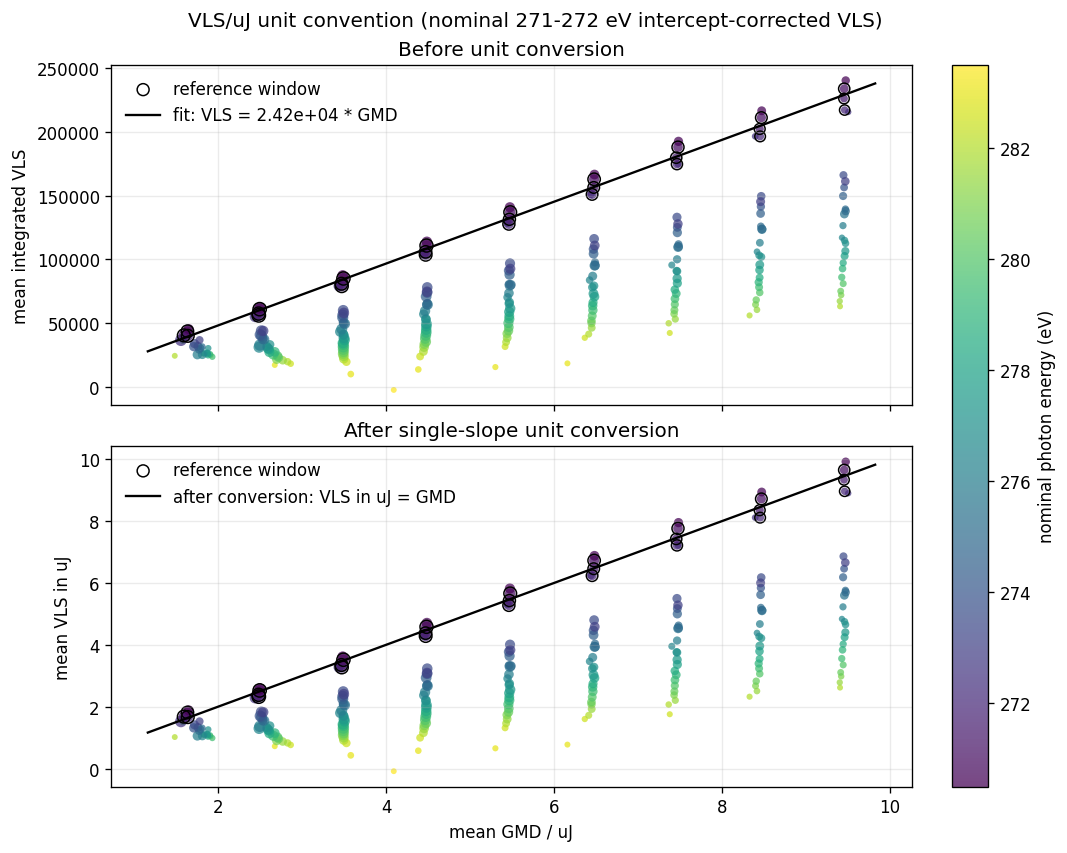

In [10]:
fig_slope, axes_slope = txas.plot_unit_scale_matplotlib(
    result,
    xlim=SLOPE_XLIM,
    raw_ylim=SLOPE_RAW_YLIM,
    scaled_ylim=SLOPE_SCALED_YLIM,
);
plt.show()


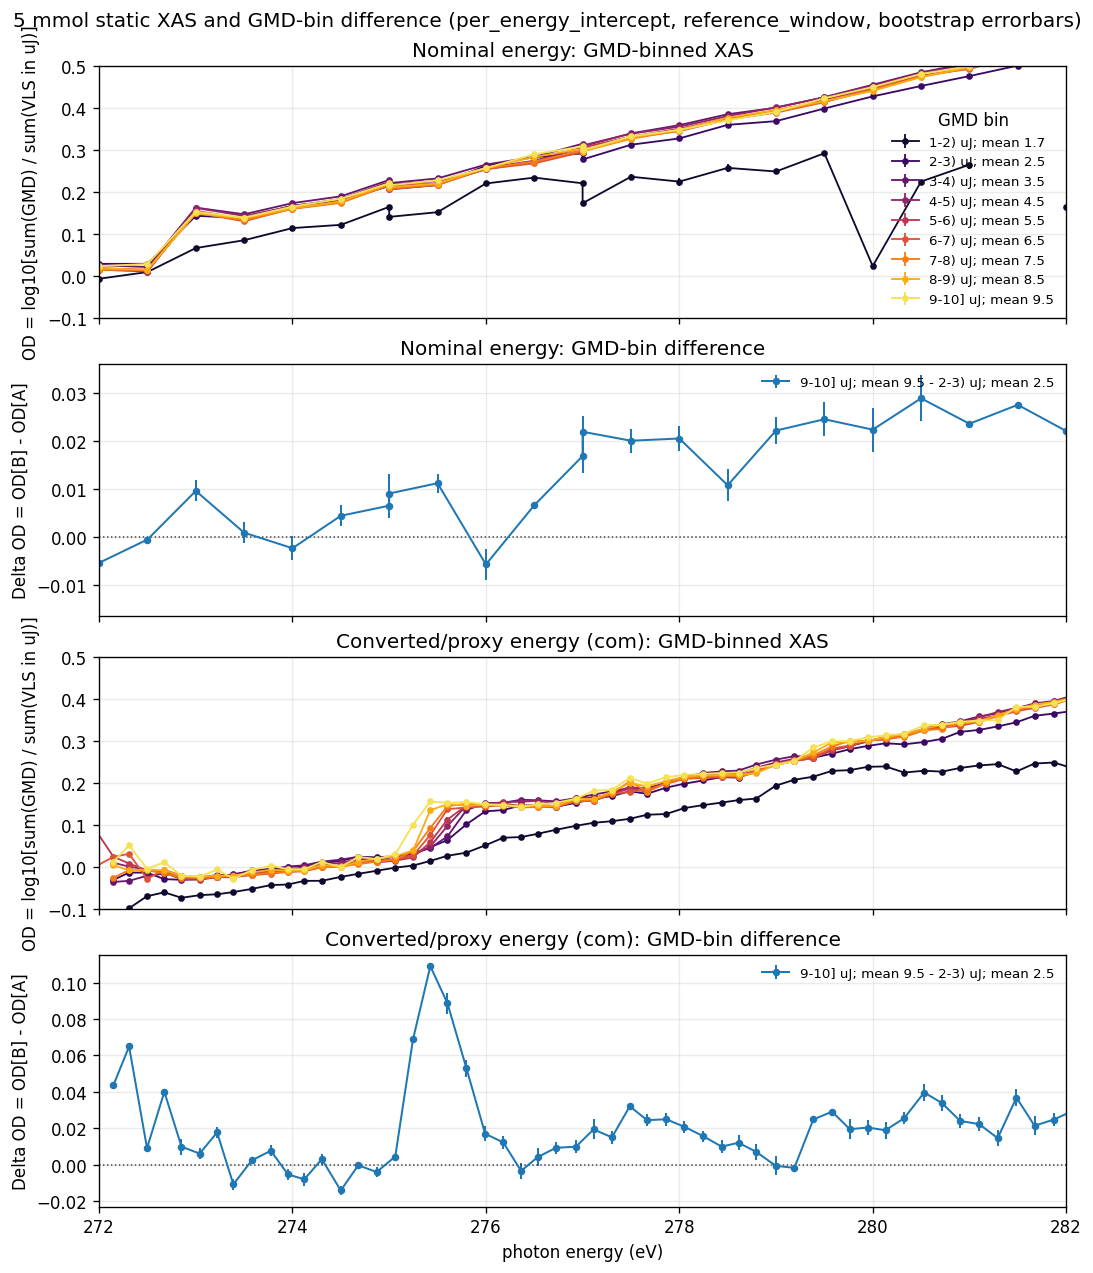

In [11]:
fig, axes = txas.plot_xas_with_gmd_difference_matplotlib(
    result,
    bootstrap=bootstrap,
    bin_a=DIFF_BIN_A,
    bin_b=DIFF_BIN_B,
    nominal_xlim=MATPLOTLIB_XLIM,
    converted_xlim=MATPLOTLIB_XLIM,
    xas_nominal_ylim=NOMINAL_XAS_YLIM,
    delta_nominal_ylim=NOMINAL_DELTA_YLIM,
    xas_converted_ylim=CONVERTED_XAS_YLIM,
    delta_converted_ylim=CONVERTED_DELTA_YLIM,
    share_xaxis=MATPLOTLIB_SHARE_X,
    show_errorbars=SHOW_ERRORBARS,
);
plt.show()


In [12]:
fig_plotly = txas.plot_xas_with_gmd_difference_plotly(
    result,
    bootstrap=bootstrap,
    bin_a=DIFF_BIN_A,
    bin_b=DIFF_BIN_B,
    nominal_xlim=PLOTLY_NOMINAL_XLIM,
    converted_xlim=PLOTLY_CONVERTED_XLIM,
    xas_nominal_ylim=NOMINAL_XAS_YLIM,
    delta_nominal_ylim=NOMINAL_DELTA_YLIM,
    xas_converted_ylim=CONVERTED_XAS_YLIM,
    delta_converted_ylim=CONVERTED_DELTA_YLIM,
    show_errorbars=SHOW_ERRORBARS,
)
fig_plotly


ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

Figure({
    'data': [{'error_y': {'array': {'bdata': ('AAAAAAAA+H/0sQOv3blVP5eh/GOcEF' ... 'AAAAD4fwAAAAAAAPh/AAAAAAAA+H8='),
                                    'dtype': 'f8'},
                          'type': 'data',
                          'visible': True},
              'legendgroup': '1-2) uJ; mean 1.7',
              'line': {'color': '#10092d', 'width': 1.4},
              'marker': {'color': '#10092d', 'size': 5},
              'mode': 'lines+markers',
              'name': '1-2) uJ; mean 1.7',
              'showlegend': True,
              'type': 'scatter',
              'x': {'bdata': ('AAAAAADgcEAAAAAAAOhwQAAAAAAA8H' ... 'AAALBxQAAAAAAAuHFAAAAAAADAcUA='),
                    'dtype': 'f8'},
              'xaxis': 'x',
              'y': {'bdata': ('AAAAAAAA+H8TKVs9F0Wtv1D7RlU296' ... 'AAAAD4fwAAAAAAAPh/AAAAAAAA+H8='),
                    'dtype': 'f8'},
              'yaxis': 'y'},
             {'error_y': {'array': {'bdata': ('AAAAAAAA+H+xTG2x8hxNP6xfyj6qhk' ... 'AAAAD4fwAAAAAAAPh/AAAAAAAA+H8='),
                                    'dtype': 'f8'},
                          'type': 'data',
                          'visible': True},
              'legendgroup': '2-3) uJ; mean 2.5',
              'line': {'color': '#3b0964', 'width': 1.4},
              'marker': {'color': '#3b0964', 'size': 5},
              'mode': 'lines+markers',
              'name': '2-3) uJ; mean 2.5',
              'showlegend': True,
              'type': 'scatter',
              'x': {'bdata': ('AAAAAADgcEAAAAAAAOhwQAAAAAAA8H' ... 'AAALBxQAAAAAAAuHFAAAAAAADAcUA='),
                    'dtype': 'f8'},
              'xaxis': 'x',
              'y': {'bdata': ('AAAAAAAA+H9hrTbL0o+Lv8jJlWBx3n' ... '6kRjniPwAAAAAAAPh/AAAAAAAA+H8='),
                    'dtype': 'f8'},
              'yaxis': 'y'},
             {'error_y': {'array': {'bdata': ('AAAAAAAA+H+8WJkzMdtLP3fSfTQHSk' ... 'n3AcKRPwAAAAAAAPh/AAAAAAAA+H8='),
                                    'dtype': 'f8'},
                          'type': 'data',
                          'visible': True},
              'legendgroup': '3-4) uJ; mean 3.5',
              'line': {'color': '#67166e', 'width': 1.4},
              'marker': {'color': '#67166e', 'size': 5},
              'mode': 'lines+markers',
              'name': '3-4) uJ; mean 3.5',
              'showlegend': True,
              'type': 'scatter',
              'x': {'bdata': ('AAAAAADgcEAAAAAAAOhwQAAAAAAA8H' ... 'AAALBxQAAAAAAAuHFAAAAAAADAcUA='),
                    'dtype': 'f8'},
              'xaxis': 'x',
              'y': {'bdata': ('AAAAAAAA+H9KRKyAA9+Pv+5rr3bcqW' ... 'UppI3tPwAAAAAAAPh/AAAAAAAA+H8='),
                    'dtype': 'f8'},
              'yaxis': 'y'},
             {'error_y': {'array': {'bdata': ('AAAAAAAA+H/QFl2+9TJOPxDNl22tb0' ... 'AAAAD4fwAAAAAAAPh/AAAAAAAA+H8='),
                                    'dtype': 'f8'},
                          'type': 'data',
                          'visible': True},
              'legendgroup': '4-5) uJ; mean 4.5',
              'line': {'color': '#922568', 'width': 1.4},
              'marker': {'color': '#922568', 'size': 5},
              'mode': 'lines+markers',
              'name': '4-5) uJ; mean 4.5',
              'showlegend': True,
              'type': 'scatter',
              'x': {'bdata': ('AAAAAADgcEAAAAAAAOhwQAAAAAAA8H' ... 'AAALBxQAAAAAAAuHFAAAAAAADAcUA='),
                    'dtype': 'f8'},
              'xaxis': 'x',
              'y': {'bdata': ('AAAAAAAA+H9ToxWui+GUv4w3ko9I4o' ... 'sIjDDsPwAAAAAAAPh/AAAAAAAA+H8='),
                    'dtype': 'f8'},
              'yaxis': 'y'},
             {'error_y': {'array': {'bdata': ('AAAAAAAA+H/gs50yMF9OP+5gWg2j80' ... 'AAAAD4fwAAAAAAAPh/AAAAAAAA+H8='),
                                    'dtype': 'f8'},
                          'type': 'data',
                          'visible': True},
              'legendgroup': '5-6) uJ; mean 5.5',
              'line': {'color': '#bc3754', 'width': 1.4},
              '